### Подключение библиотек

In [2]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LinearRegression, Ridge, Lasso, RidgeCV, LassoCV,ElasticNetCV, ElasticNet
from sklearn.metrics import mean_squared_error, r2_score

sns.set_theme(style="whitegrid")

In [3]:
df = pd.read_csv("used_car_price_dataset_extended.csv")

df['mileage_cat'] = df['mileage_kmpl'].apply(lambda x:
    'low' if x <= 10 
    else 'medium' if x <= 20 else 'high'
    )

car_impact = df.groupby('mileage_cat')['price_usd'].median()

df = pd.get_dummies(df, drop_first=True)

X = df.drop('price_usd', axis=1)
y = df['price_usd']

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

scaler = StandardScaler()
X_train=scaler.fit_transform(X_train) 
X_test=scaler.transform(X_test)

corr_matrix = X.corr()

print("Матрица корреляций")
display(corr_matrix.round(2))

Матрица корреляций


,make_year,mileage_kmpl,engine_cc,owner_count,accidents_reported,fuel_type_Electric,fuel_type_Petrol,brand_Chevrolet,brand_Ford,brand_Honda,...,transmission_Manual,color_Blue,color_Gray,color_Red,color_Silver,color_White,service_history_Partial,insurance_valid_Yes,mileage_cat_low,mileage_cat_medium
make_year,1.00,-0.01,-0.02,-0.02,-0.01,-0.01,0.02,0.01,0.00,0.00,...,0.00,0.01,0.00,0.01,-0.02,-0.00,-0.02,0.00,-0.00,0.01
mileage_kmpl,-0.01,1.00,-0.00,-0.01,0.00,0.01,-0.01,-0.01,-0.00,-0.00,...,-0.01,0.01,-0.01,-0.01,-0.01,-0.01,-0.01,0.02,-0.50,-0.51
engine_cc,-0.02,-0.00,1.00,-0.00,-0.01,-0.01,-0.01,0.00,0.02,-0.01,...,-0.00,0.01,0.01,0.00,-0.01,-0.02,0.00,-0.01,0.02,-0.01
owner_count,-0.02,-0.01,-0.00,1.00,-0.01,-0.00,0.01,-0.01,0.01,-0.02,...,0.01,0.01,-0.01,-0.01,0.01,0.00,0.00,0.00,0.00,-0.00
accidents_reported,-0.01,0.00,-0.01,-0.01,1.00,0.01,-0.01,-0.00,-0.02,-0.01,...,-0.00,0.01,0.01,-0.01,-0.01,-0.00,0.00,-0.02,-0.02,0.02
fuel_type_Electric,-0.01,0.01,-0.01,-0.00,0.01,1.00,-0.33,-0.00,0.01,0.00,...,0.01,-0.00,-0.02,0.02,-0.01,0.01,-0.01,0.01,0.01,0.01
fuel_type_Petrol,0.02,-0.01,-0.01,0.01,-0.01,-0.33,1.00,0.01,0.00,0.01,...,0.00,0.01,-0.01,-0.01,0.02,-0.01,0.01,-0.00,0.02,-0.02
brand_Chevrolet,0.01,-0.01,0.00,-0.01,-0.00,-0.00,0.01,1.00,-0.11,-0.11,...,-0.01,0.00,0.01,0.02,-0.01,-0.01,0.00,0.00,0.00,0.01
brand_Ford,0.00,-0.00,0.02,0.01,-0.02,0.01,0.00,-0.11,1.00,-0.11,...,-0.01,-0.00,0.00,0.00,-0.02,0.01,0.01,-0.01,-0.01,0.01
brand_Honda,0.00,-0.00,-0.01,-0.02,-0.01,0.00,0.01,-0.11,-0.11,1.00,...,-0.00,-0.00,0.00,-0.00,-0.01,0.01,0.00,0.01,-0.01,0.00


Из таблицы можно понять что значения не настоящие, сгенерированные, потому что значения варируются от -0.02 до 0.01. Из-за чего линейная регрессия не даст прироста качества, т.к. каждый признак влияет на цену сам по себе

In [4]:
lr = LinearRegression()
lr.fit(X_train, y_train)

alphas_to_test = [0.1, 1.0, 10.0, 100.0, 1000.0, 2000.0, 3000.0, 5000.0, 10000.0]
ridge_cv = RidgeCV(alphas=alphas_to_test)
ridge_cv.fit(X_train, y_train)


lasso_cv =LassoCV(alphas=alphas_to_test, random_state=42)
lasso_cv.fit(X_train, y_train)
lasso =Lasso(alpha=5000.0, random_state=42)
lasso.fit(X_train, y_train)
l1_ratios = [0.1, 0.3, 0.5, 0.7, 0.9, 0.95, 0.99]
elastic_cv = ElasticNetCV(l1_ratio=l1_ratios, alphas=alphas_to_test, cv=5, random_state=42)
elastic_cv.fit(X_train, y_train)

print(f"alpha l2= {ridge_cv.alpha_}")
print(f"alpha l1 = {lasso_cv.alpha_}")
print(f"alpha l1/l2 = {elastic_cv.alpha_}")
print(f"Оптимальное соотношение L1/L2 (l1_ratio): {elastic_cv.l1_ratio_}")

print("Веса OLS")
print(np.round(lr.coef_, 0))
print("Веса Ridge (L2)")
print(np.round(ridge_cv.coef_, 0))
print("Веса Lasso (L1)")
print(np.round(lasso_cv.coef_, 0))
print("Веса Lasso (L1) (alpha = 5000)")
print(np.round(lasso.coef_, 0))
print("Веса ElasticNet:")
print(np.round(elastic_cv.coef_, 0))

alpha l2= 10.0
alpha l1 = 10.0
alpha l1/l2 = 0.1
Оптимальное соотношение L1/L2 (l1_ratio): 0.99
Веса OLS
[1247.  555. 1927. -695.    4.  904.   -2.  -25.  -24.  -14.  -27.  -19.
  -19.  -33.  -22.   -6.   -6.  -18.  -15.   10.  -16.   -3.    0.  -14.
  -36.  -66.]
Веса Ridge (L2)
[1246.  553. 1925. -694.    4.  902.   -3.  -25.  -24.  -13.  -27.  -19.
  -19.  -33.  -22.   -6.   -6.  -18.  -15.   10.  -16.   -3.    0.  -14.
  -38.  -67.]
Веса Lasso (L1)
[1237.  574. 1917. -685.    0.  894.   -0.   -0.   -0.    0.   -0.   -0.
    0.   -6.   -0.    3.   -0.   -0.   -0.   11.   -0.    0.    0.   -4.
   -8.  -37.]
Веса Lasso (L1) (alpha = 5000)
[0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0.
 0. 0.]
Веса ElasticNet:
[1246.  553. 1925. -694.    4.  903.   -3.  -24.  -23.  -13.  -26.  -18.
  -18.  -32.  -21.   -5.   -6.  -18.  -15.   10.  -16.   -3.    0.  -14.
  -37.  -67.]


Самые большие веса у make_year, mileage_kmpl, engine_cc, owner_count. У всех кроме owner_count положительное число, значит все кроме owner_count увеличивают цену.

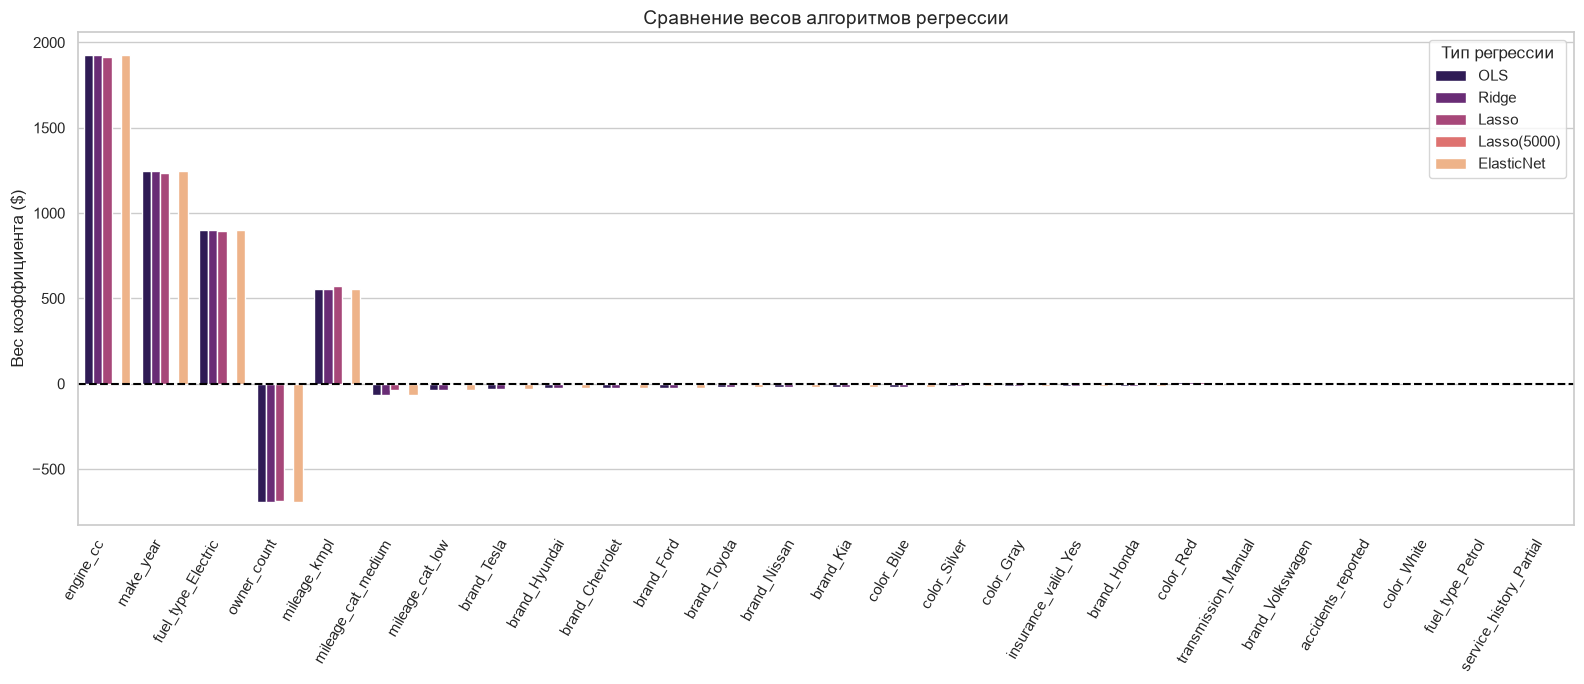

In [7]:
weights_df = pd.DataFrame({
    "Признак": X.columns,
    "OLS": lr.coef_,
    "Ridge": ridge_cv.coef_,
    "Lasso": lasso_cv.coef_,
    "Lasso(5000)": lasso.coef_,
    "ElasticNet": elastic_cv.coef_
})

# Сортируем от самого сильного влияния к слабому для красоты графика
weights_df = weights_df.reindex(weights_df["OLS"].abs().sort_values(ascending=False).index)

weights_melted = weights_df.melt(
    id_vars="Признак", var_name="Модель", value_name="Влияние на цену (Вес)"
)

plt.figure(figsize=(16, 7))
sns.barplot(
    data=weights_melted,
    x="Признак",
    y="Влияние на цену (Вес)",
    hue="Модель",
    palette="magma"
)

plt.axhline(0, color="black", lw=1.5, ls="--")
plt.title("Сравнение весов алгоритмов регрессии", fontsize=14)
plt.ylabel("Вес коэффициента ($)", fontsize=12)
plt.xlabel("")
plt.xticks(rotation=60, ha="right")
plt.legend(title="Тип регрессии")
plt.tight_layout()
plt.show()


На графике видно, что engine_cc, make_year, fuel_type_Electric, mileage_kmpl увеличивают цену автомобиля, а снижает цену только owner_count. Остальные признаки не дают существенной разницы и их можно не учитывать

In [8]:
print(f"R2 для OLS: {r2_score(y_test, lr.predict(X_test)):.4f}")
print(f"R2 для Ridge: {r2_score(y_test, ridge_cv.predict(X_test)):.4f}")
print(f"R2 для Lasso: {r2_score(y_test, lasso_cv.predict(X_test)):.4f}")
print(f"R2 для Lasso: {r2_score(y_test, lasso.predict(X_test)):.4f}")
print(f"R2 для ElasticNet: {r2_score(y_test, elastic_cv.predict(X_test)):.4f}")

R2 для OLS: 0.8764
R2 для Ridge: 0.8764
R2 для Lasso: 0.8764
R2 для Lasso: -0.0009
R2 для ElasticNet: 0.8764


4 модели показали одинаковое качество ~88%, кроме Lasso у которого высокая alpha, которая уменьшаяет все коэффициенты в 0 из-за чего теперь ни один признак не влияет на цену и модель просто угадывает её. 